# 05 - The full benchmark: v3 and v4 against QUANT + ExtraTrees and the published classifiers

v3 (the cheap TabPFN, notebook 03) and v4 (the supervised extractor, notebook 04) on the paper's 142 datasets x 30
resamples: against QUANT + ExtraTrees (v1), on the 108 datasets never used in development, and against the published
classifiers of the bake-off redux. Settings and commands: `experiments.md`, v1, v3 and v4.

## 1. Data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import (BETTER, EQUAL, GROUP_COLORS, MUTED, OTHERS, REPO, RESULTS_DIR, TEXT, VERSION_COLORS, WORSE,
                    load_runs, signed, style, wdl_counts)

style()
NAMES = {"v1": "QUANT + ExtraTrees (v1)", "v3": "v3 (cheap TabPFN)", "v4": "v4 (supervised extractor)"}
RESULT_COLORS = VERSION_COLORS                      # one colour per result (notebooks/common.py)
DATASETS = (REPO / "original" / "code" / "ucr142.txt").read_text().split()   # the 142 datasets of the paper

v1_runs = load_runs(RESULTS_DIR / "v1_ucr142_onecore-cpu.csv")      # one row per run
v1_all_runs = load_runs(RESULTS_DIR / "v1_ucr142_allcores-cpu.csv")  # the same method on all CPU cores
v3_runs = load_runs(RESULTS_DIR / "v3_tabpfn-e2f200-both_ucr142_allcores-gpu.csv")   # notebook 03
v4_runs = load_runs(RESULTS_DIR / "v4_tabpfn-e2f200_ucr142_allcores-gpu.csv")        # notebook 04

def wide(runs):
    """One row per dataset (in the order of the paper's list), one column per resample."""
    return runs.pivot(index="dataset", columns="resample", values="accuracy").loc[DATASETS]

ACCURACY = {"v1": wide(v1_runs), "v3": wide(v3_runs), "v4": wide(v4_runs)}
MEAN = pd.DataFrame({name: table.mean(axis=1) for name, table in ACCURACY.items()})   # mean of the 30 per dataset
same = (wide(v1_all_runs) == ACCURACY["v1"]).sum().sum()
print(f"QUANT + ExtraTrees, all cores vs one core: identical accuracy in {same} of {ACCURACY['v1'].size} runs")
print(f"runs finished: v3 {(v3_runs['status'] == 'ok').sum()} of {len(v3_runs)}, "
      f"v4 {(v4_runs['status'] == 'ok').sum()} of {len(v4_runs)}, "
      f"v1 {(v1_runs['status'] == 'ok').sum()} of {len(v1_runs)}; missing values: "
      f"{sum(int(t.isna().sum().sum()) for t in ACCURACY.values())}")

QUANT + ExtraTrees, all cores vs one core: identical accuracy in 4260 of 4260 runs
runs finished: v3 4260 of 4260, v4 4260 of 4260, v1 4260 of 4260; missing values: 0


## 2. Mean accuracy and mean rank

Each dataset = the mean of its 30 resamples; rank 1 = the most accurate on a dataset.

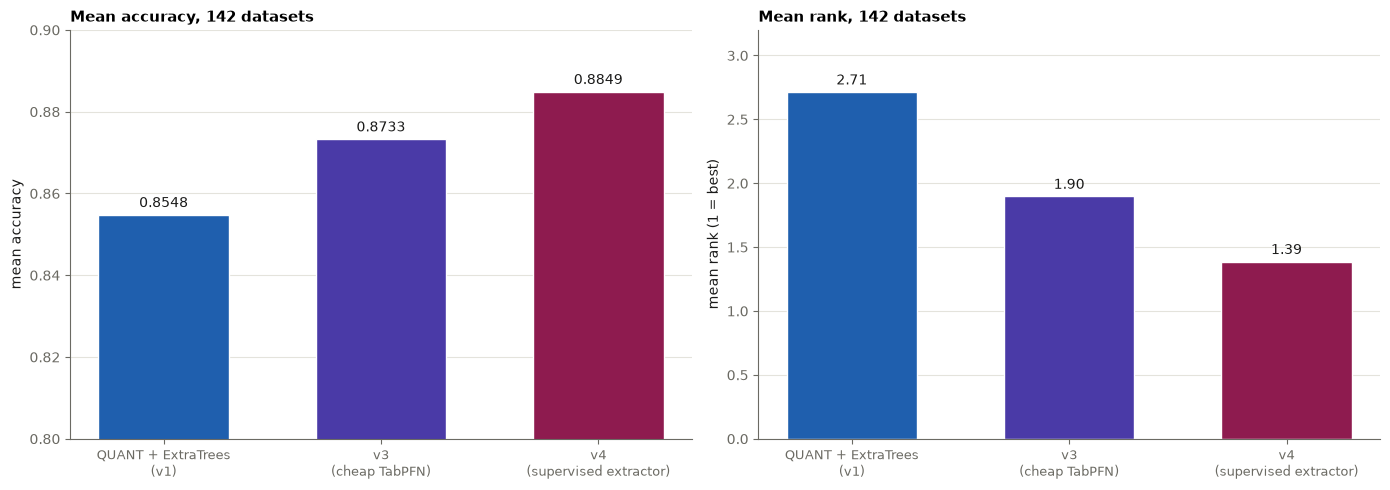

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
bars = ax.bar(range(len(NAMES)), MEAN[list(NAMES)].mean(), 0.6, color=[RESULT_COLORS[n] for n in NAMES],
              edgecolor="white")
ax.bar_label(bars, fmt="{:.4f}", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(NAMES)), [NAMES[n].replace(" (", "\n(") for n in NAMES], fontsize=9)
ax.set_ylim(0.80, 0.90)
ax.set_ylabel("mean accuracy")
ax.set_title("Mean accuracy, 142 datasets", loc="left")

ax = axes[1]
ranks = MEAN.rank(axis=1, ascending=False).mean()       # 1 = the most accurate on a dataset
bars = ax.bar(range(len(NAMES)), [ranks[n] for n in NAMES], 0.6, color=[RESULT_COLORS[n] for n in NAMES],
              edgecolor="white")
ax.bar_label(bars, fmt="{:.2f}", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(NAMES)), [NAMES[n].replace(" (", "\n(") for n in NAMES], fontsize=9)
ax.set_ylim(0, 3.2)
ax.set_ylabel("mean rank (1 = best)")
ax.set_title("Mean rank, 142 datasets", loc="left")
fig.tight_layout()
plt.show()

## 3. Per dataset: v3 and v4 vs QUANT + ExtraTrees, and v4 vs v3

Left: one point per dataset; above the diagonal the first-named result is more accurate. Right: the change on every
dataset, sorted, with the Wilcoxon signed-rank p-value.

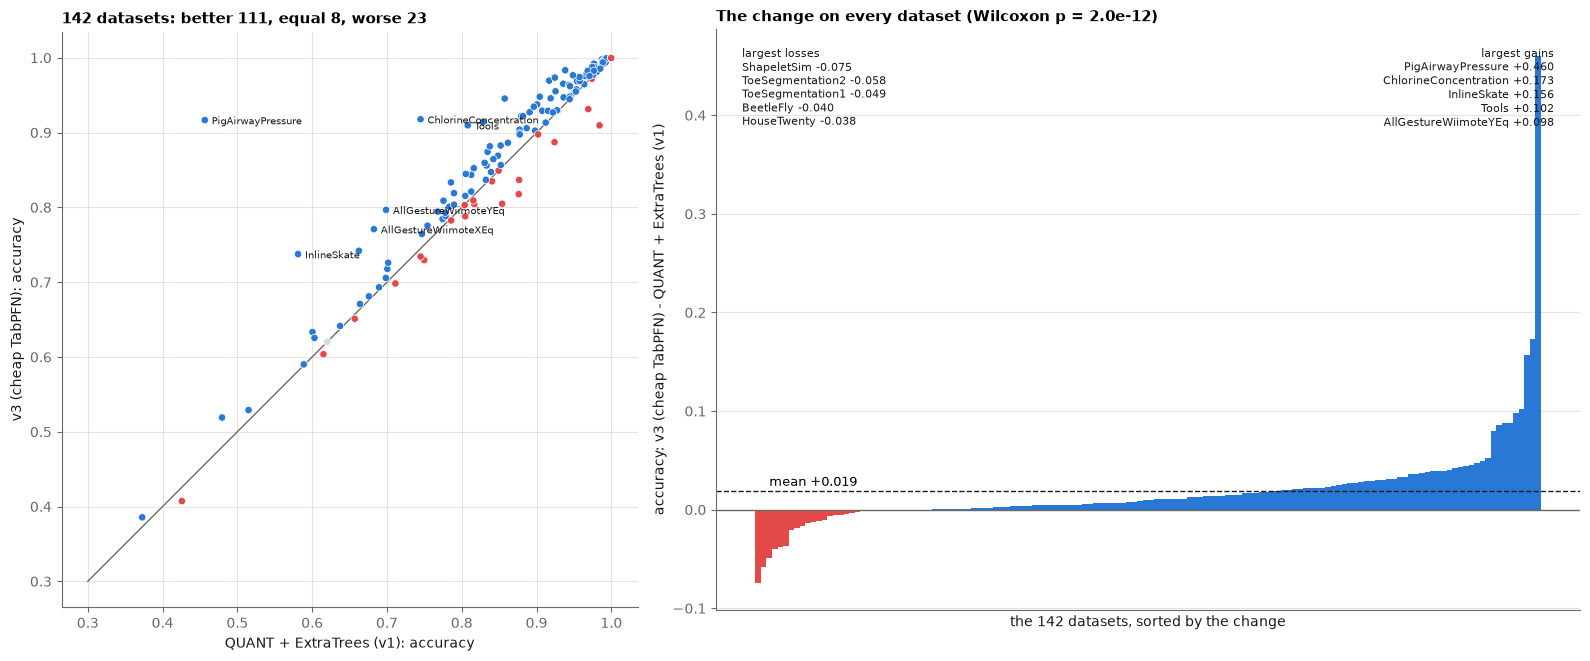

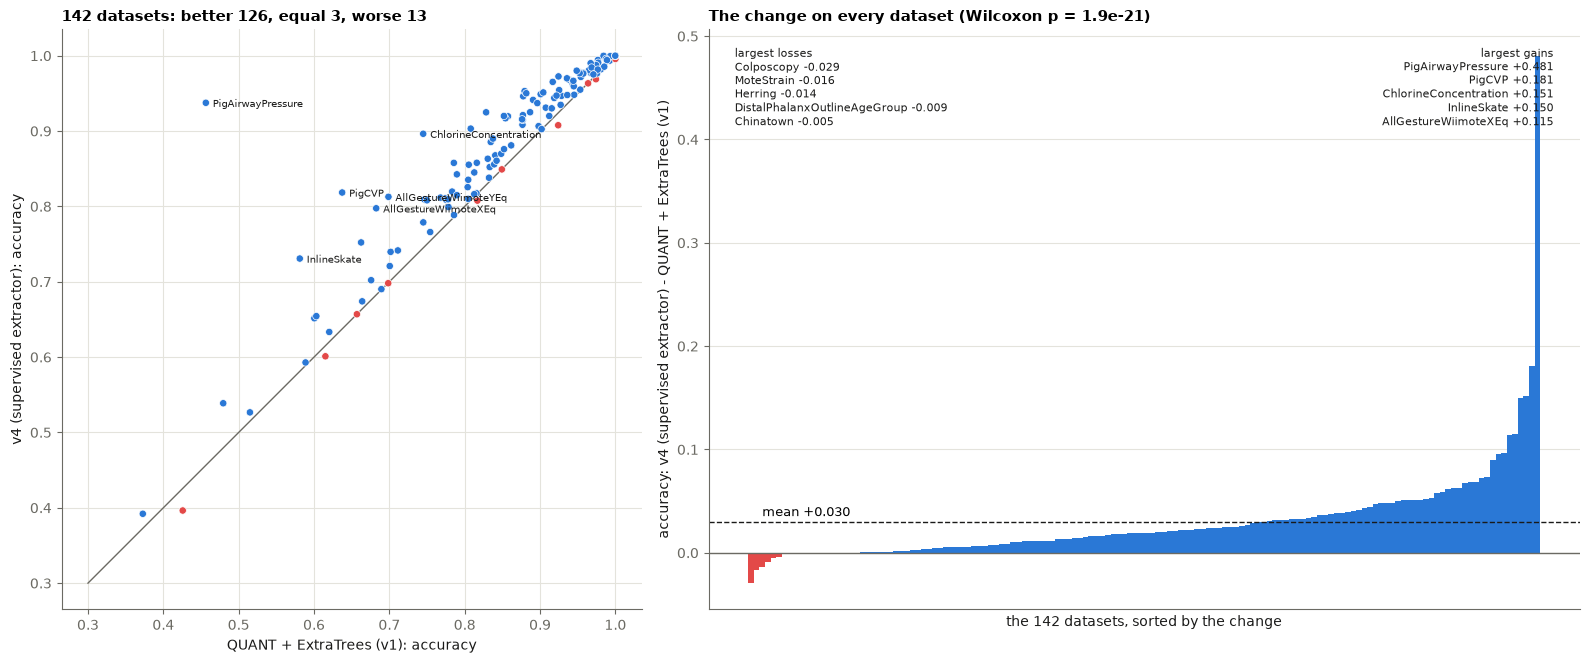

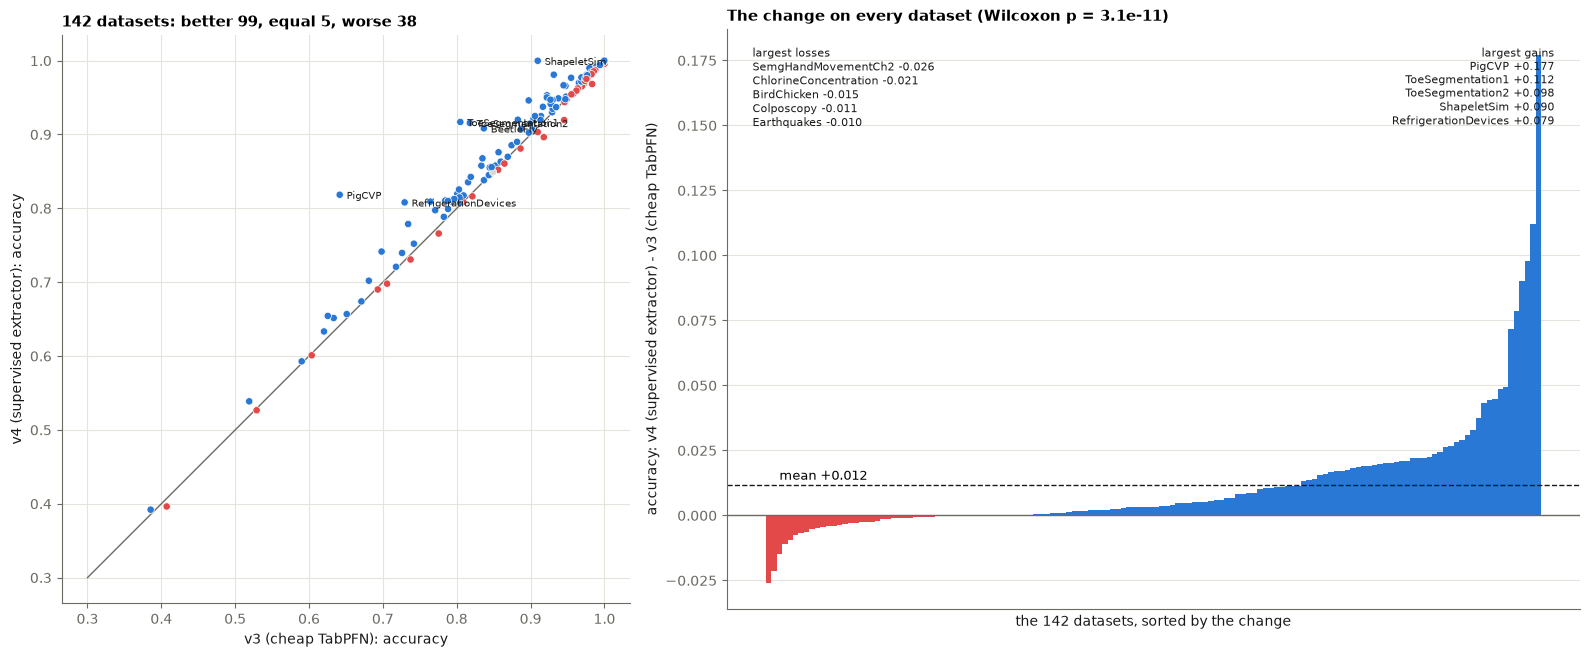

In [3]:
def compare(a, b):
    """The per-dataset comparison of result a against result b (all 142 datasets): one row of plots."""
    change = MEAN[a] - MEAN[b]
    better, equal, worse = wdl_counts(change)
    p_value = stats.wilcoxon(MEAN[a], MEAN[b]).pvalue
    colors = [BETTER if x > 1e-12 else WORSE if x < -1e-12 else EQUAL for x in change]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.5]})
    ax = axes[0]
    ax.plot([0.3, 1.0], [0.3, 1.0], color=MUTED, linewidth=1, zorder=1)    # the diagonal: equal accuracy
    ax.scatter(MEAN[b], MEAN[a], s=28, c=colors, edgecolor="white", linewidth=0.5, zorder=3)
    for name in change.abs().sort_values().index[-6:]:                     # the largest changes, named
        ax.annotate(name, (MEAN.loc[name, b], MEAN.loc[name, a]), xytext=(5, -3), textcoords="offset points",
                    fontsize=7.5, color=TEXT)
    ax.set_xlabel(f"{NAMES[b]}: accuracy")
    ax.set_ylabel(f"{NAMES[a]}: accuracy")
    ax.set_title(f"142 datasets: better {better}, equal {equal}, worse {worse}", loc="left")
    ax.grid(True, axis="both")
    ax.set_aspect("equal")

    ax = axes[1]
    order = change.sort_values()
    ax.bar(range(len(order)), order, 1.0, color=[BETTER if x > 1e-12 else WORSE if x < -1e-12 else EQUAL for x in order])
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axhline(change.mean(), color=TEXT, linewidth=1, linestyle="--")
    ax.annotate(f"mean {signed(change.mean())}", (2, change.mean()), xytext=(0, 4), textcoords="offset points", fontsize=9)
    gains = "\n".join(f"{n} {signed(x)}" for n, x in order.tail(5)[::-1].items())      # the 5 largest gains and losses
    losses = "\n".join(f"{n} {signed(x)}" for n, x in order.head(5).items())
    ax.text(0.97, 0.97, f"largest gains\n{gains}", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=TEXT)
    ax.text(0.03, 0.97, f"largest losses\n{losses}", transform=ax.transAxes, ha="left", va="top", fontsize=8, color=TEXT)
    ax.set_xticks([])
    ax.set_xlabel("the 142 datasets, sorted by the change")
    ax.set_ylabel(f"accuracy: {NAMES[a]} - {NAMES[b]}")
    ax.set_title(f"The change on every dataset (Wilcoxon p = {p_value:.1e})", loc="left")
    fig.tight_layout()
    plt.show()

compare("v3", "v1")
compare("v4", "v1")
compare("v4", "v3")

## 4. Time per run

Transforms + feature selection + fit + predict. QUANT + ExtraTrees on one core (the paper's setting) and on all cores
(the fair comparison: the same cores as v3 and v4, which also use the GPU).

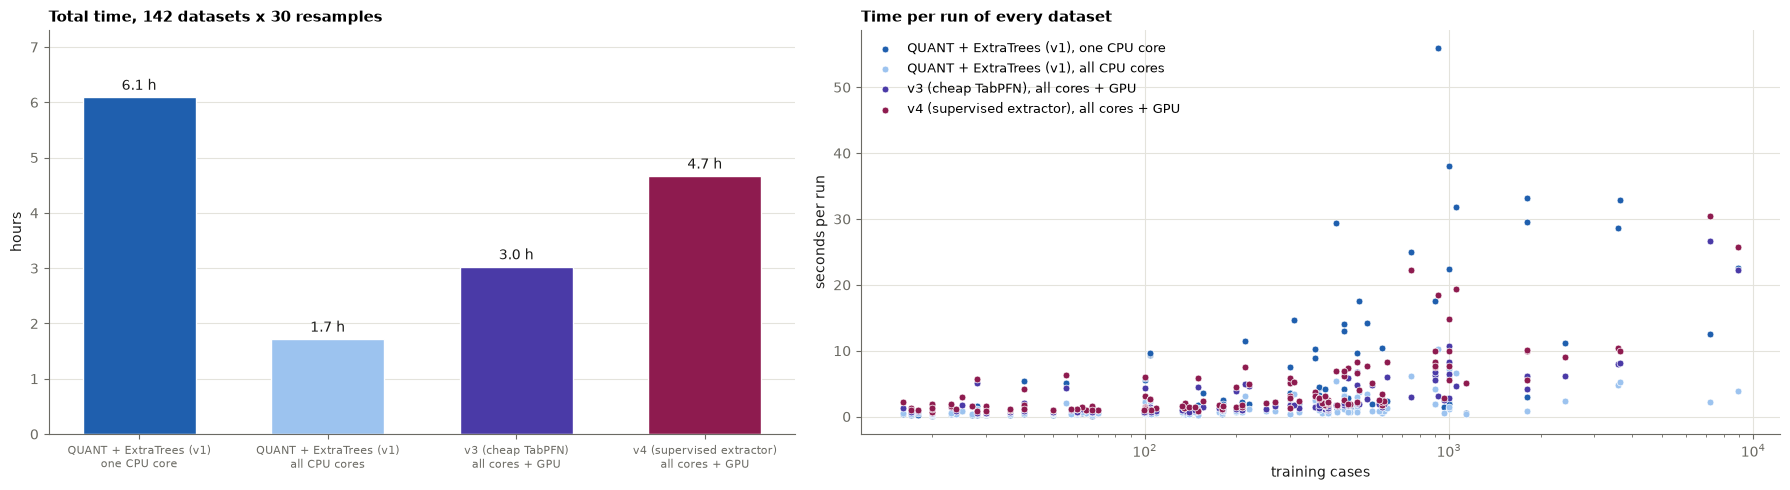

In [4]:
n_train = v3_runs.groupby("dataset")["n_train"].first()               # training cases of every dataset
RUNS = {"v1": v1_runs, "v1 all cores": v1_all_runs, "v3": v3_runs, "v4": v4_runs}
LABELS = {"v1": "QUANT + ExtraTrees (v1)\none CPU core", "v1 all cores": "QUANT + ExtraTrees (v1)\nall CPU cores",
          "v3": "v3 (cheap TabPFN)\nall cores + GPU", "v4": "v4 (supervised extractor)\nall cores + GPU"}
time = pd.DataFrame({name: runs.groupby("dataset")["total_time"].mean() for name, runs in RUNS.items()}).loc[DATASETS]
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1.3, 1.6]})
ax = axes[0]
totals = [runs["total_time"].sum() / 3600 for runs in RUNS.values()]
bars = ax.bar(range(len(RUNS)), totals, 0.6, color=[RESULT_COLORS[n] for n in RUNS], edgecolor="white")
ax.bar_label(bars, fmt="{:.1f} h", padding=3, fontsize=10, color=TEXT)
ax.set_xticks(range(len(RUNS)), [LABELS[n] for n in RUNS], fontsize=8)
ax.set_ylim(0, max(totals) * 1.2)
ax.set_ylabel("hours")
ax.set_title("Total time, 142 datasets x 30 resamples", loc="left")

ax = axes[1]
for name in RUNS:
    ax.scatter(n_train[time.index], time[name], s=24, color=RESULT_COLORS[name], edgecolor="white",
               linewidth=0.5, label=LABELS[name].replace("\n", ", "), zorder=3)
ax.set_xscale("log")
ax.set_xlabel("training cases")
ax.set_ylabel("seconds per run")
ax.set_title("Time per run of every dataset", loc="left")
ax.grid(True, axis="both")
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 5. The datasets used for development vs the others

34 datasets were used to choose v3's and v4's settings (`dev34.txt`), the other 108 never were (`heldout108.txt`).
Labels: the mean change, better / equal / worse and the Wilcoxon p-value.

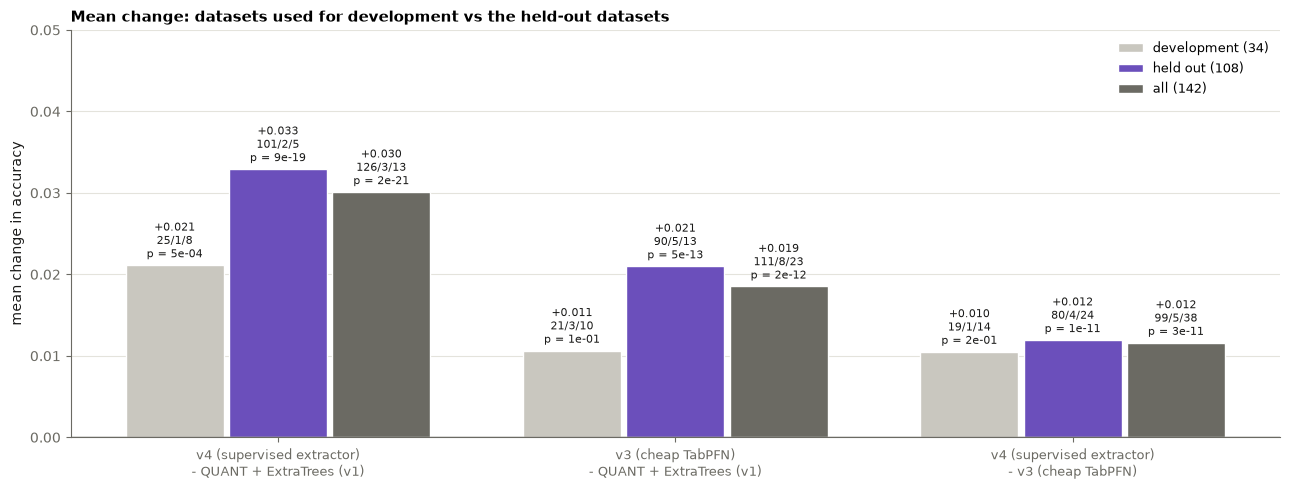

In [5]:
from common import dataset_list

DEV = [d for d in DATASETS if d in set(dataset_list("dev34"))]             # used to choose the settings
HELDOUT = [d for d in DATASETS if d in set(dataset_list("heldout108"))]    # never used to choose anything
SUBSETS = {f"development ({len(DEV)})": DEV, f"held out ({len(HELDOUT)})": HELDOUT, f"all ({len(DATASETS)})": DATASETS}
SUBSET_COLORS = [GROUP_COLORS["development"], GROUP_COLORS["held out"], GROUP_COLORS["all"]]
PAIRS = [("v4", "v1"), ("v3", "v1"), ("v4", "v3")]

fig, ax = plt.subplots(figsize=(13, 5))
width = 0.26
for s, (subset, names) in enumerate(SUBSETS.items()):
    for p, (a, b) in enumerate(PAIRS):
        change = MEAN.loc[names, a] - MEAN.loc[names, b]
        better, equal, worse = wdl_counts(change)
        p_value = stats.wilcoxon(MEAN.loc[names, a], MEAN.loc[names, b]).pvalue
        x = p + (s - 1) * width
        ax.bar(x, change.mean(), width * 0.95, color=SUBSET_COLORS[s], edgecolor="white",
               label=subset if p == 0 else None)
        ax.annotate(f"{signed(change.mean())}\n{better}/{equal}/{worse}\np = {p_value:.0e}", (x, change.mean()),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, color=TEXT)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(range(len(PAIRS)), [f"{NAMES[a]}\n- {NAMES[b]}" for a, b in PAIRS], fontsize=9)
ax.set_ylim(0, 0.05)
ax.set_ylabel("mean change in accuracy")
ax.set_title("Mean change: datasets used for development vs the held-out datasets", loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

## 6. Against the published classifiers of the bake-off redux

The bake-off redux's published accuracies of 11 classifiers (the 112 UCR datasets, 30 resamples; downloaded, see
`experiments.md`). Second figure: the critical-difference diagram (mean ranks; a bar joins the results whose pairwise
Wilcoxon tests are not significant after Holm's correction).

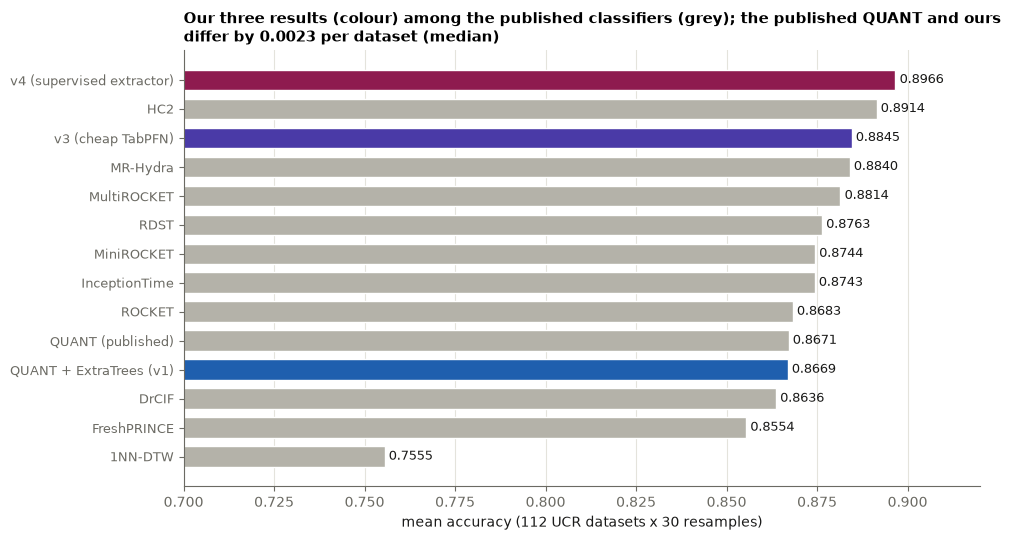

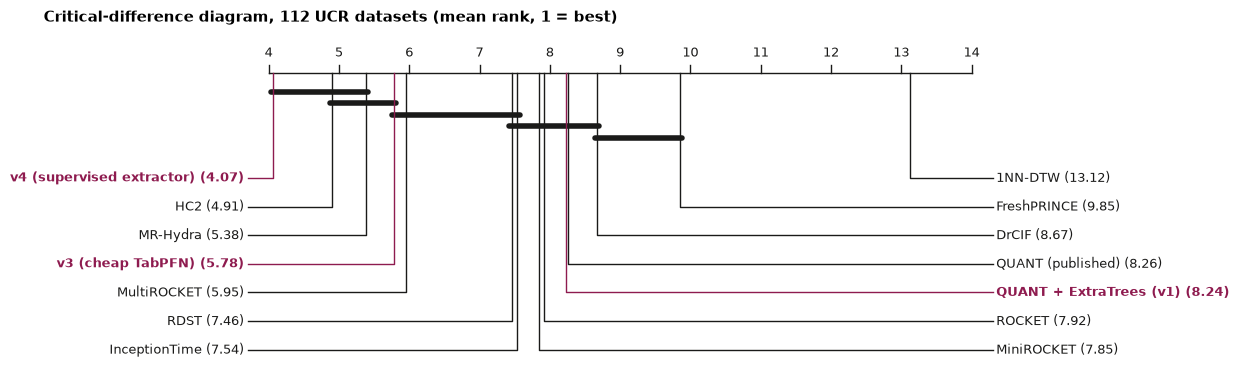

In [6]:
# the published accuracies as downloaded: one file per classifier, one row per dataset, one column per resample
# (MR = MultiROCKET)
REF_MEAN = pd.DataFrame({{"MR": "MultiROCKET"}.get(f.name[:-13], f.name[:-13]): pd.read_csv(f, index_col=0).mean(axis=1)
                         for f in sorted((RESULTS_DIR / "bakeoff-redux").glob("*_accuracy.csv"))})
UCR112 = [d for d in DATASETS if d in REF_MEAN.index]
BENCH = REF_MEAN.loc[UCR112].rename(columns={"QUANT": "QUANT (published)"})
for n in NAMES:
    BENCH[NAMES[n]] = MEAN.loc[UCR112, n]
OURS = list(NAMES.values())
check = (BENCH["QUANT (published)"] - BENCH[NAMES["v1"]]).abs()

means = BENCH.mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [RESULT_COLORS[next(k for k, v in NAMES.items() if v == n)] if n in OURS else OTHERS for n in means.index]
bars = ax.barh(range(len(means)), means, 0.7, color=colors, edgecolor="white")
ax.bar_label(bars, fmt="{:.4f}", padding=3, fontsize=9, color=TEXT)
ax.set_yticks(range(len(means)), means.index, fontsize=9)
ax.set_xlim(0.70, 0.92)
ax.set_xlabel("mean accuracy (112 UCR datasets x 30 resamples)")
ax.set_title("Our three results (colour) among the published classifiers (grey); the published QUANT and ours\n"
             f"differ by {check.median():.4f} per dataset (median)", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()


def cd_diagram(scores, highlight=(), alpha=0.05, title=""):
    """Critical-difference diagram (as aeon's plot_critical_difference): mean ranks, and bars joining the classifiers
    whose pairwise Wilcoxon signed-rank tests are not significant after Holm's correction."""
    ranks = scores.rank(axis=1, ascending=False).mean().sort_values()
    names, k = list(ranks.index), len(ranks)
    pairs = [(i, j) for i in range(k) for j in range(i + 1, k)]
    p = [1.0 if (scores[names[i]] - scores[names[j]]).abs().max() < 1e-12
         else stats.wilcoxon(scores[names[i]], scores[names[j]]).pvalue for i, j in pairs]
    same = np.ones((k, k), dtype=bool)                   # True: no significant difference
    for step, index in enumerate(np.argsort(p)):         # Holm: reject while p <= alpha / (tests left)
        if p[index] > alpha / (len(p) - step):
            break
        i, j = pairs[index]
        same[i, j] = same[j, i] = False
    cliques = []                                         # the longest runs of neighbours without a difference
    for i in range(k):
        j = i
        while j + 1 < k and same[i:j + 2, i:j + 2].all():
            j += 1
        if j > i and not any(a <= i and j <= b for a, b in cliques):
            cliques.append((i, j))
    lo, hi = np.floor(ranks.min()), np.ceil(ranks.max())
    half = (k + 1) // 2
    fig, ax = plt.subplots(figsize=(13, 1.6 + 0.32 * half))
    ax.plot([lo, hi], [0, 0], color=TEXT, linewidth=1)
    for r in np.arange(lo, hi + 1):
        ax.plot([r, r], [0, 0.08], color=TEXT, linewidth=1)
        ax.text(r, 0.14, f"{r:.0f}", ha="center", va="bottom", fontsize=9, color=TEXT)
    for c, (i, j) in enumerate(cliques):
        y = -0.2 - 0.12 * c
        ax.plot([ranks.iloc[i] - 0.03, ranks.iloc[j] + 0.03], [y, y], color=TEXT, linewidth=4, solid_capstyle="round")
    top = -0.2 - 0.12 * len(cliques)                     # the names start below the clique bars
    for n, (name, r) in enumerate(ranks.items()):
        left = n < half
        y = top - 0.3 * ((n if left else k - 1 - n) + 1)
        edge = lo - 0.3 if left else hi + 0.3
        color, weight = (RESULT_COLORS["v4"], "bold") if name in highlight else (TEXT, "normal")
        ax.plot([r, r, edge], [0, y, y], color=color, linewidth=1)
        ax.text(edge + (-0.05 if left else 0.05), y, f"{name} ({r:.2f})", ha="right" if left else "left",
                va="center", fontsize=9, color=color, fontweight=weight)
    ax.set_xlim(lo - 3.2, hi + 3.2)
    ax.set_ylim(top - 0.3 * (half + 0.5), 0.45)
    ax.axis("off")
    ax.set_title(title, loc="left")
    fig.tight_layout()
    plt.show()
    return ranks, cliques


ranks, cliques = cd_diagram(BENCH, highlight=OURS,
                            title="Critical-difference diagram, 112 UCR datasets (mean rank, 1 = best)")

## 7. How sure are the differences? Confidence intervals and the spread over resamples

Left: 95% bootstrap intervals of the mean changes (the datasets resampled 10,000 times). Right: the standard
deviation of every dataset over its 30 resamples; below the diagonal v4 varies less.

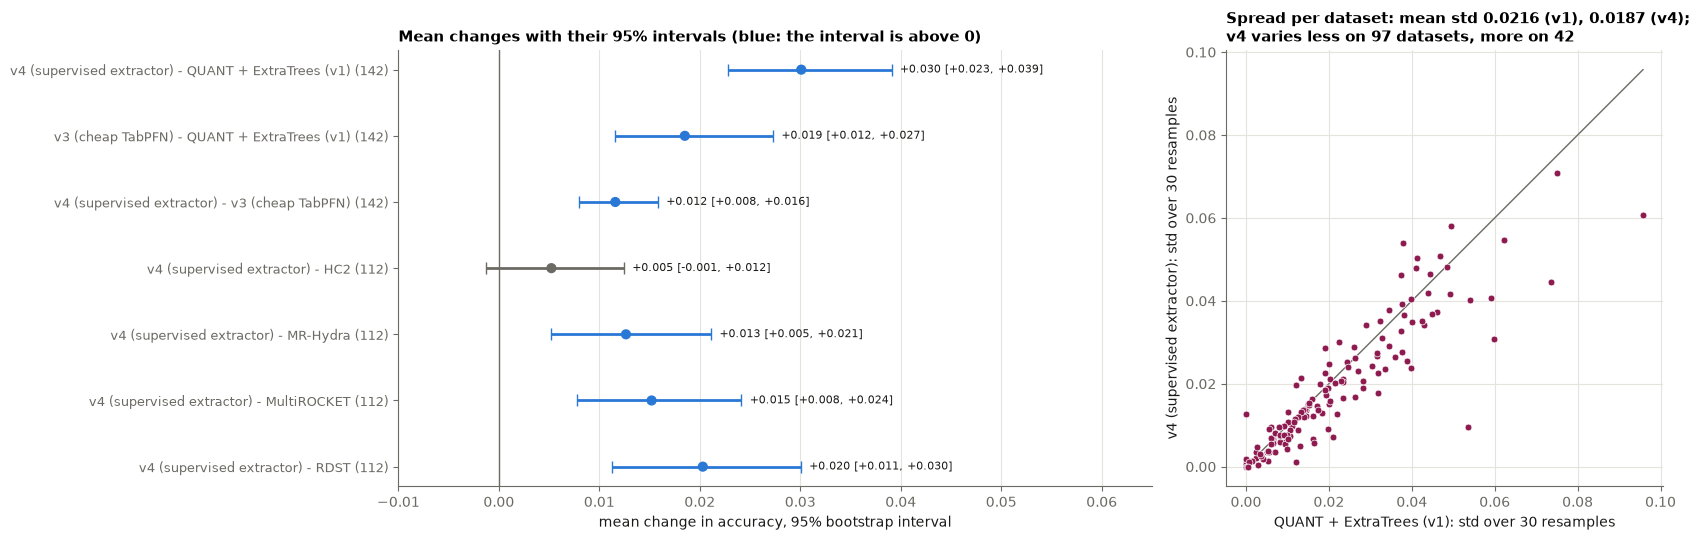

In [7]:
rng = np.random.default_rng(0)


def bootstrap_ci(change, n=10_000):
    """Mean change and its 95% bootstrap interval (the datasets resampled with replacement)."""
    change = np.asarray(change)
    means = change[rng.integers(0, len(change), (n, len(change)))].mean(axis=1)
    return change.mean(), *np.percentile(means, [2.5, 97.5])


INTERVALS = {f"{NAMES['v4']} - {NAMES['v1']} (142)": MEAN["v4"] - MEAN["v1"],
             f"{NAMES['v3']} - {NAMES['v1']} (142)": MEAN["v3"] - MEAN["v1"],
             f"{NAMES['v4']} - {NAMES['v3']} (142)": MEAN["v4"] - MEAN["v3"]}
for other in ["HC2", "MR-Hydra", "MultiROCKET", "RDST"]:
    INTERVALS[f"{NAMES['v4']} - {other} (112)"] = BENCH[NAMES["v4"]] - BENCH[other]
ci = pd.DataFrame([bootstrap_ci(change) for change in INTERVALS.values()], index=list(INTERVALS),
                  columns=["mean", "low", "high"])

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
y = np.arange(len(ci))[::-1]
colors = [BETTER if row["low"] > 0 else WORSE if row["high"] < 0 else MUTED for _, row in ci.iterrows()]
for yy, color, (_, row) in zip(y, colors, ci.iterrows()):     # one interval at a time (one colour each)
    ax.errorbar(row["mean"], yy, xerr=[[row["mean"] - row["low"]], [row["high"] - row["mean"]]], fmt="none",
                ecolor=color, elinewidth=2, capsize=4)
ax.scatter(ci["mean"], y, color=colors, s=40, zorder=3)
for yy, (_, row) in zip(y, ci.iterrows()):
    ax.annotate(f"{signed(row['mean'])} [{signed(row['low'])}, {signed(row['high'])}]", (row["high"], yy),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=TEXT)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, ci.index, fontsize=9)
ax.set_xlim(-0.01, 0.065)
ax.set_xlabel("mean change in accuracy, 95% bootstrap interval")
ax.set_title("Mean changes with their 95% intervals (blue: the interval is above 0)", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")

ax = axes[1]
spread = pd.DataFrame({name: table.std(axis=1) for name, table in ACCURACY.items()})
less, _, more = wdl_counts(spread["v1"] - spread["v4"])
ax.plot([0, spread.max().max()], [0, spread.max().max()], color=MUTED, linewidth=1, zorder=1)
ax.scatter(spread["v1"], spread["v4"], s=24, color=RESULT_COLORS["v4"], edgecolor="white", linewidth=0.5, zorder=3)
ax.set_xlabel(f"{NAMES['v1']}: std over 30 resamples")
ax.set_ylabel(f"{NAMES['v4']}: std over 30 resamples")
ax.set_title(f"Spread per dataset: mean std {spread['v1'].mean():.4f} (v1), {spread['v4'].mean():.4f} (v4);\n"
             f"v4 varies less on {less} datasets, more on {more}", loc="left")
ax.grid(True, axis="both")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## 8. Beyond accuracy: balanced accuracy, AUROC and log loss

From the predicted probabilities. The log loss (lower is better) rewards probabilities that can be trusted;
ExtraTrees' vote shares are often 0 or 1 (clipped at 1e-15).

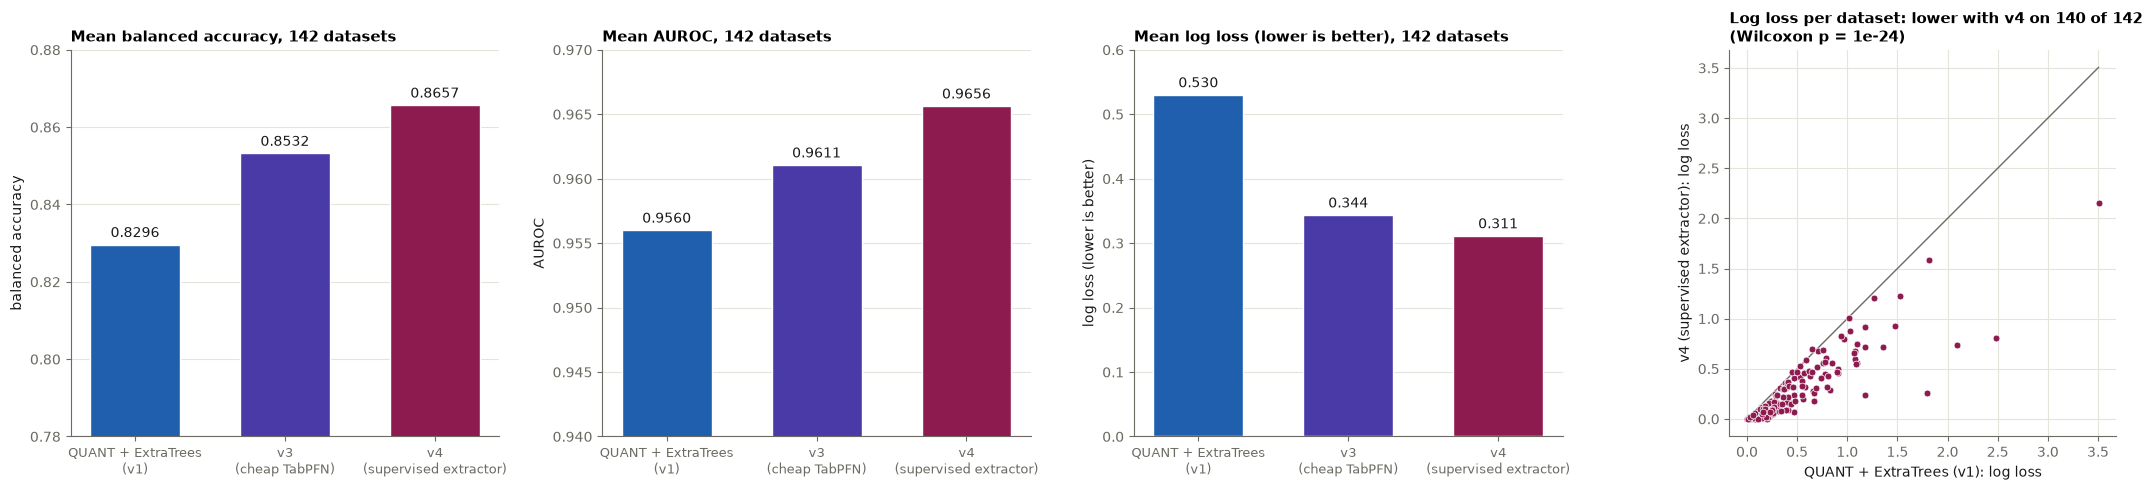

In [8]:
METRICS = {"balanced_accuracy": "balanced accuracy", "auroc": "AUROC", "log_loss": "log loss (lower is better)"}
PER_DATASET = {name: runs.groupby("dataset")[list(METRICS)].mean().loc[DATASETS]
               for name, runs in {"v1": v1_runs, "v3": v3_runs, "v4": v4_runs}.items()}
change = PER_DATASET["v4"]["log_loss"] - PER_DATASET["v1"]["log_loss"]
better, equal, worse = wdl_counts(-change)
p_value = stats.wilcoxon(PER_DATASET["v4"]["log_loss"], PER_DATASET["v1"]["log_loss"]).pvalue

fig, axes = plt.subplots(1, 4, figsize=(22, 5), gridspec_kw={"width_ratios": [1, 1, 1, 1.2]})
for ax, metric, ylim, fmt in [(axes[0], "balanced_accuracy", (0.78, 0.88), "{:.4f}"),
                              (axes[1], "auroc", (0.94, 0.97), "{:.4f}"),
                              (axes[2], "log_loss", (0, 0.6), "{:.3f}")]:
    values = [PER_DATASET[n][metric].mean() for n in NAMES]
    bars = ax.bar(range(len(NAMES)), values, 0.6, color=[RESULT_COLORS[n] for n in NAMES], edgecolor="white")
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=10, color=TEXT)
    ax.set_xticks(range(len(NAMES)), [NAMES[n].replace(" (", "\n(") for n in NAMES], fontsize=9)
    ax.set_ylim(*ylim)
    ax.set_ylabel(METRICS[metric])
    ax.set_title(f"Mean {METRICS[metric]}, 142 datasets", loc="left")
ax = axes[3]
top = max(PER_DATASET["v1"]["log_loss"].max(), PER_DATASET["v4"]["log_loss"].max())
ax.plot([0, top], [0, top], color=MUTED, linewidth=1, zorder=1)
ax.scatter(PER_DATASET["v1"]["log_loss"], PER_DATASET["v4"]["log_loss"], s=24, color=RESULT_COLORS["v4"],
           edgecolor="white", linewidth=0.5, zorder=3)
ax.set_xlabel(f"{NAMES['v1']}: log loss")
ax.set_ylabel(f"{NAMES['v4']}: log loss")
ax.set_title(f"Log loss per dataset: lower with v4 on {better} of {len(DATASETS)}\n(Wilcoxon p = {p_value:.0e})",
             loc="left")
ax.grid(True, axis="both")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## 9. Conclusions

- **v4 is the most accurate:** 0.8849 against 0.8733 (v3) and 0.8548 (QUANT + ExtraTrees); better than QUANT +
  ExtraTrees on 126 of 142 datasets (p = 2e-21) and than v3 on 99 (p = 3e-11); its losses are at most -0.029, on
  datasets with few training cases.
- **Not an artefact of the development:** on the 108 held-out datasets +0.033 over QUANT + ExtraTrees (101/2/5) and
  +0.012 over v3.
- **Against the published classifiers (112 UCR datasets):** the best mean accuracy (0.8966; HC2 0.8914, MR-Hydra
  0.8840) and mean rank; tied with HC2 and MR-Hydra after Holm, better than the other nine.
- **How sure:** 95% intervals [+0.023, +0.039] against QUANT + ExtraTrees and [-0.001, +0.012] against HC2; v4 varies
  less over the resamples.
- **Better probabilities:** log loss 0.311 against 0.530 (lower on 140 of 142 datasets).
- **Time:** 4.7 hours for all 4,260 runs (v3 3.0), against 1.7 for QUANT + ExtraTrees on the same cores.

Caveats: one seed per resample; TabPFN is pretrained and uses the GPU.